# Detecção de Fraude em Cartão de Crédito

Projeto de estudo: treinar modelos que detectam fraude em transações reais de cartão de crédito,
um problema em que **a fraude é rara e a acurácia engana**.

**Base de dados:** transações de cartões europeus em setembro de 2013 (284.807 transações).
- `Time`: segundos desde a primeira transação da base
- `Amount`: valor da transação
- `V1` a `V28`: variáveis transformadas por PCA (para proteger a privacidade)
- `Class`: resposta, **1 = fraude**, **0 = normal**

**Roteiro do notebook**
1. Explorar os dados
2. Preparar (log do valor, padronização, separação estratificada)
3. Treinar (Regressão Logística, Random Forest, XGBoost)
4. Avaliar (relatório de classificação, curva ROC, curva de precisão e recall)
5. Ajustar (`Pipeline`, limiar de decisão, `GridSearchCV`)
6. Explicar (importância das variáveis e SHAP)
7. Evoluções (undersampling × oversampling, Random Forest no Pipeline com ajuste de limiar)

## 0. Bibliotecas

No Google Colab tudo já vem instalado. Para rodar localmente: `pip install -r requirements.txt`.

In [1]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', module='tqdm')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
import shap

SEED = 42
pd.set_option('display.float_format', '{:.4f}'.format)

# Cores fixas por modelo (mesma cor = mesmo modelo em todos os gráficos)
CORES = {
    'Regressão Logística': '#2a78d6',
    'Random Forest': '#eb6834',
    'XGBoost': '#1baf7a',
}
COR_NORMAL, COR_FRAUDE = '#2a78d6', '#eb6834'
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True})

## 1. Explorar

Assim como na aula, o link vai direto para o `pd.read_csv`, sem baixar o arquivo
(ele tem cerca de 150 MB e passa do limite de 100 MB do GitHub, por isso não fica no repositório).

In [2]:
URL = 'https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv'
df = pd.read_csv(URL)
print(f'{df.shape[0]:,} linhas x {df.shape[1]} colunas')
df.head()

284,807 linhas x 31 colunas


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [3]:
print('Valores ausentes:', df.isna().sum().sum())
df[['Time', 'Amount', 'Class']].describe()

Valores ausentes: 0


,Time,Amount,Class
count,284807.0000,284807.0000,284807.0000
mean,94813.8596,88.3496,0.0017
std,47488.1460,250.1201,0.0415
min,0.0000,0.0000,0.0000
25%,54201.5000,5.6000,0.0000
50%,84692.0000,22.0000,0.0000
75%,139320.5000,77.1650,0.0000
max,172792.0000,25691.1600,1.0000


### Proporção de fraudes

In [4]:
print(df['Class'].value_counts())
df['Class'].value_counts(normalize=True).mul(100).round(3).rename('% das transações')

Class
0    284315
1       492
Name: count, dtype: int64


Class
0   99.8270
1    0.1730
Name: % das transações, dtype: float64

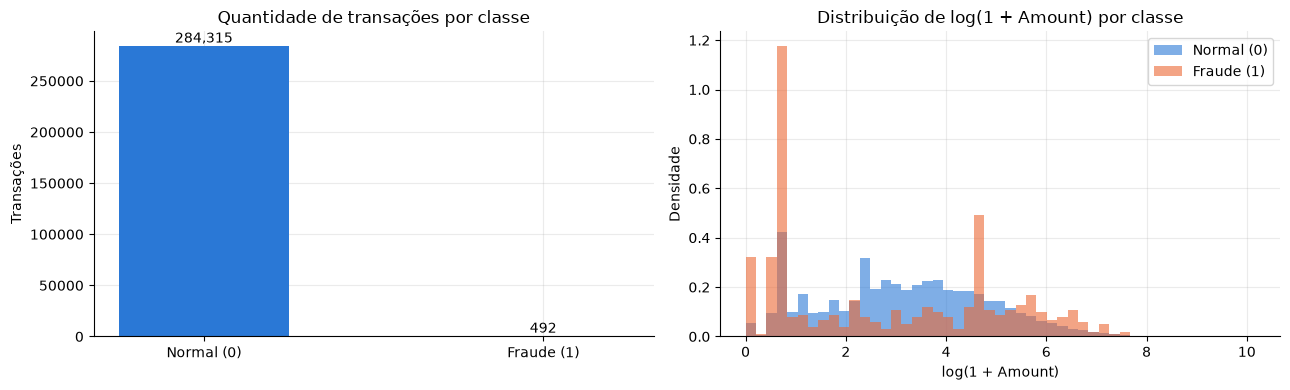

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

contagem = df['Class'].value_counts().sort_index()
axes[0].bar(['Normal (0)', 'Fraude (1)'], contagem.values, color=[COR_NORMAL, COR_FRAUDE], width=0.5)
for i, v in enumerate(contagem.values):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')
axes[0].set_title('Quantidade de transações por classe')
axes[0].set_ylabel('Transações')

bins = np.linspace(0, np.log1p(df['Amount'].max()), 50)
axes[1].hist(np.log1p(df.loc[df.Class == 0, 'Amount']), bins=bins, density=True, alpha=0.6, color=COR_NORMAL, label='Normal (0)')
axes[1].hist(np.log1p(df.loc[df.Class == 1, 'Amount']), bins=bins, density=True, alpha=0.6, color=COR_FRAUDE, label='Fraude (1)')
axes[1].set_title('Distribuição de log(1 + Amount) por classe')
axes[1].set_xlabel('log(1 + Amount)')
axes[1].set_ylabel('Densidade')
axes[1].legend()
plt.tight_layout()
plt.show()

A barra de fraude quase some no gráfico: são só **492 fraudes em 284.807 transações (0,17%)**.

### Por que a acurácia engana

Um "modelo" que responde **sempre "não é fraude"** já acerta quase tudo. Vamos provar com um `DummyClassifier`:

In [6]:
dummy = DummyClassifier(strategy='most_frequent').fit(df.drop(columns='Class'), df['Class'])
pred_dummy = dummy.predict(df.drop(columns='Class'))
print(f"Acurácia do modelo que nunca acusa fraude: {accuracy_score(df['Class'], pred_dummy):.4%}")
print(f"Recall da fraude (fraudes encontradas):    {recall_score(df['Class'], pred_dummy):.0%}")

Acurácia do modelo que nunca acusa fraude: 99.8273%
Recall da fraude (fraudes encontradas):    0%


99,83% de acurácia e **nenhuma fraude encontrada**. Por isso, daqui em diante olhamos para a **classe de fraude**:

| Métrica | Pergunta que responde |
|---|---|
| **Recall** | De todas as fraudes reais, quantas o modelo encontrou? |
| **Precisão** | De tudo que o modelo marcou como fraude, quanto era fraude mesmo? |
| **F1** | Equilíbrio (média harmônica) entre precisão e recall |
| **PR-AUC** | Área sob a curva de precisão e recall: resume o modelo em todos os limiares |

## 2. Preparar

1. **Log do valor:** `Amount` é muito assimétrico (muitas compras pequenas e poucas enormes). `np.log1p` comprime a escala.
2. **Separação treino/teste com `stratify`:** garante a mesma proporção de fraudes (~0,17%) nos dois conjuntos.
3. **Padronização com `StandardScaler`:** coloca `Time` e `log_amount` na mesma escala das variáveis do PCA.
   O scaler é ajustado **só no treino**, para o teste não "vazar" informação.

In [7]:
df['log_amount'] = np.log1p(df['Amount'])

X = df.drop(columns=['Class', 'Amount'])   # V1..V28, Time e log_amount
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

print(f'Treino: {len(X_train):,} transações | fraudes: {y_train.sum()} ({y_train.mean():.3%})')
print(f'Teste:  {len(X_test):,} transações | fraudes: {y_test.sum()} ({y_test.mean():.3%})')

Treino: 227,845 transações | fraudes: 394 (0.173%)
Teste:  56,962 transações | fraudes: 98 (0.172%)


In [8]:
scaler = StandardScaler()
X_train_sc = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_sc = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)
X_train_sc[['Time', 'log_amount']].describe().loc[['mean', 'std']]

,Time,log_amount
mean,-0.0000,-0.0000
std,1.0000,1.0000


## 3. Treinar

- **Regressão Logística:** baseline simples e rápido.
- **Random Forest** com `class_weight='balanced'`: cada fraude passa a "pesar" ~580 vezes mais que uma transação normal no treino.
- **XGBoost:** boosting de árvores; usamos `scale_pos_weight` (o equivalente do `class_weight` no XGBoost).

In [9]:
peso_fraude = (y_train == 0).sum() / (y_train == 1).sum()
print(f'Peso da fraude (normais / fraudes no treino): {peso_fraude:.0f}')

modelos = {
    'Regressão Logística': LogisticRegression(max_iter=1000, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced',
                                            min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                             scale_pos_weight=peso_fraude, eval_metric='aucpr',
                             n_jobs=-1, random_state=SEED),
}

for nome, modelo in modelos.items():
    modelo.fit(X_train_sc, y_train)
    print(f'{nome}: treinado')

Peso da fraude (normais / fraudes no treino): 577


Regressão Logística: treinado


Random Forest: treinado


XGBoost: treinado


## 4. Avaliar

### Relatório de classificação (limiar padrão de 0,5)
Repare que a linha `accuracy` fica perto de 1 em todos, enquanto a linha **Fraude (1)** muda bastante.

In [10]:
probas = {nome: m.predict_proba(X_test_sc)[:, 1] for nome, m in modelos.items()}

for nome, proba in probas.items():
    pred = (proba >= 0.5).astype(int)
    print(f'===== {nome} =====')
    print(classification_report(y_test, pred, target_names=['Normal (0)', 'Fraude (1)'], digits=3))

===== Regressão Logística =====
              precision    recall  f1-score   support

  Normal (0)      0.999     1.000     1.000     56864
  Fraude (1)      0.831     0.653     0.731        98

    accuracy                          0.999     56962
   macro avg      0.915     0.826     0.866     56962
weighted avg      0.999     0.999     0.999     56962

===== Random Forest =====
              precision    recall  f1-score   support

  Normal (0)      1.000     1.000     1.000     56864
  Fraude (1)      0.759     0.837     0.796        98

    accuracy                          0.999     56962
   macro avg      0.879     0.918     0.898     56962
weighted avg      0.999     0.999     0.999     56962

===== XGBoost =====
              precision    recall  f1-score   support

  Normal (0)      1.000     1.000     1.000     56864
  Fraude (1)      0.828     0.837     0.832        98

    accuracy                          0.999     56962
   macro avg      0.914     0.918     0.916     56

In [11]:
def metricas(y_true, proba, limiar=0.5):
    pred = (proba >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        'Acurácia': accuracy_score(y_true, pred),
        'Precisão (fraude)': precision_score(y_true, pred, zero_division=0),
        'Recall (fraude)': recall_score(y_true, pred),
        'F1 (fraude)': f1_score(y_true, pred),
        'ROC-AUC': roc_auc_score(y_true, proba),
        'PR-AUC': average_precision_score(y_true, proba),
        'Fraudes pegas': f'{tp}/{tp + fn}',
        'Alarmes falsos': fp,
    }

comparacao = pd.DataFrame({nome: metricas(y_test, p) for nome, p in probas.items()}).T
comparacao

,Acurácia,Precisão (fraude),Recall (fraude),F1 (fraude),ROC-AUC,PR-AUC,Fraudes pegas,Alarmes falsos
Regressão Logística,0.9992,0.8312,0.6531,0.7314,0.9595,0.7386,64/98,13
Random Forest,0.9993,0.7593,0.8367,0.7961,0.9642,0.8559,82/98,26
XGBoost,0.9994,0.8283,0.8367,0.8325,0.9873,0.8659,82/98,17


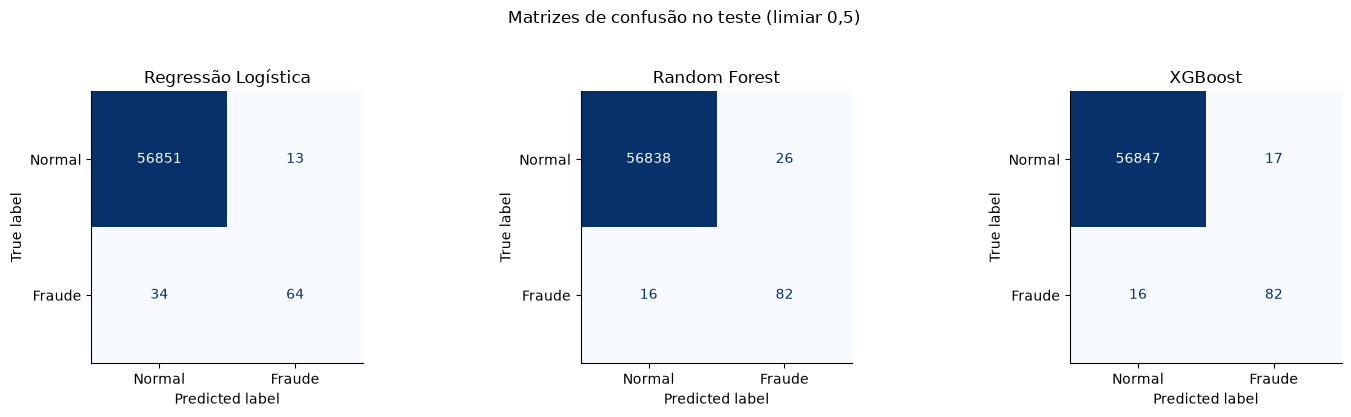

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nome, proba) in zip(axes, probas.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (proba >= 0.5).astype(int), display_labels=['Normal', 'Fraude'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nome)
    ax.grid(False)
plt.suptitle('Matrizes de confusão no teste (limiar 0,5)', y=1.03)
plt.tight_layout()
plt.show()

### Curva ROC × Curva de Precisão e Recall

A curva ROC usa a taxa de falsos positivos, que fica minúscula porque existem ~57 mil transações normais no teste.
Por isso **todos os modelos parecem ótimos na ROC**. A curva de precisão e recall olha só para a classe de fraude
e mostra as diferenças de verdade. É a mais útil num problema desbalanceado.

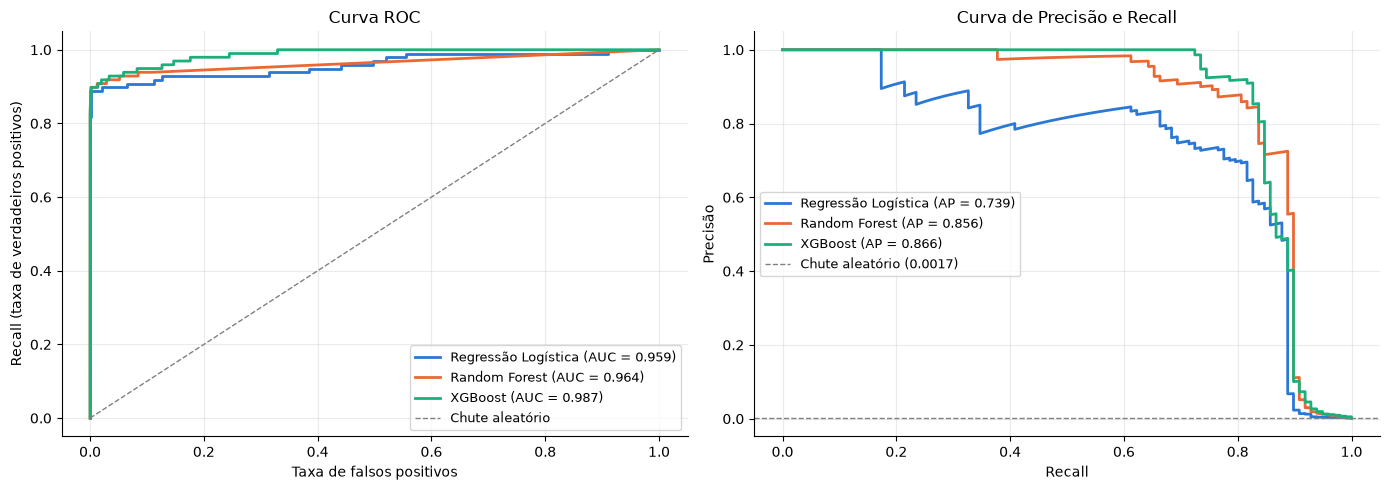

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for nome, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, lw=2, color=CORES[nome], label=f'{nome} (AUC = {roc_auc_score(y_test, proba):.3f})')
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, lw=2, color=CORES[nome], label=f'{nome} (AP = {average_precision_score(y_test, proba):.3f})')

axes[0].plot([0, 1], [0, 1], ls='--', color='gray', lw=1, label='Chute aleatório')
axes[0].set(title='Curva ROC', xlabel='Taxa de falsos positivos', ylabel='Recall (taxa de verdadeiros positivos)')
axes[1].axhline(y_test.mean(), ls='--', color='gray', lw=1, label=f'Chute aleatório ({y_test.mean():.4f})')
axes[1].set(title='Curva de Precisão e Recall', xlabel='Recall', ylabel='Precisão')
for ax in axes:
    ax.legend(loc='best', fontsize=9)
plt.tight_layout()
plt.show()

**O que os números mostram (limiar 0,5, 98 fraudes no teste):**
- A **acurácia** fica entre 99,92% e 99,94% nos três modelos: ela **não ajuda a escolher**.
- A **Regressão Logística** sem pesos tem boa precisão (83%) mas só encontra **64 das 98 fraudes** (recall de 65%).
- **Random Forest** e **XGBoost** encontram **82 das 98 fraudes** (recall de 84%). O XGBoost erra menos (17 alarmes falsos contra 26),
  e por isso tem o melhor F1 (0,83) e a melhor área sob a curva de precisão e recall (PR-AUC 0,866).
- Na curva ROC os três parecem quase iguais (AUC de 0,96 a 0,99). Na curva de precisão e recall a diferença aparece:
  a Regressão Logística perde precisão bem antes das árvores.

## 5. Ajustar

### 5.1 Pipeline: padronização + modelo juntos
No `Pipeline` o `StandardScaler` é reajustado dentro de cada etapa da validação cruzada, sem vazamento de dados.
Ele recebe os dados **brutos** (`X_train`), não os já padronizados.

In [14]:
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('modelo', LogisticRegression(max_iter=1000, random_state=SEED)),
])
pipe_lr.fit(X_train, y_train)
proba_pipe = pipe_lr.predict_proba(X_test)[:, 1]

### 5.2 Baixando o limiar de decisão de 0,5 para 0,3
O `predict` marca fraude quando a probabilidade é ≥ 0,5. Em fraude, **deixar passar uma fraude custa mais caro
do que revisar uma transação normal**, então vale baixar o limiar para pegar mais fraudes.

In [15]:
pd.DataFrame({f'limiar {l}': metricas(y_test, proba_pipe, l) for l in [0.5, 0.3]}).T

,Acurácia,Precisão (fraude),Recall (fraude),F1 (fraude),ROC-AUC,PR-AUC,Fraudes pegas,Alarmes falsos
limiar 0.5,0.9992,0.8312,0.6531,0.7314,0.9595,0.7386,64/98,13
limiar 0.3,0.9991,0.7556,0.6939,0.7234,0.9595,0.7386,68/98,22


### 5.3 GridSearchCV escolhendo pelo recall
Testamos a força da regularização (`C`) e o peso da classe. A métrica de escolha é `scoring='recall'`, e a validação
cruzada é estratificada para cada dobra ter fraudes.

In [16]:
grid = GridSearchCV(
    pipe_lr,
    param_grid={
        'modelo__C': [0.01, 0.1, 1, 10],
        'modelo__class_weight': [None, 'balanced'],
    },
    scoring='recall',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print('Melhores parâmetros:', grid.best_params_)
print(f'Recall médio na validação cruzada: {grid.best_score_:.3f}')
pd.DataFrame(grid.cv_results_)[['param_modelo__C', 'param_modelo__class_weight', 'mean_test_score']] \
    .astype({'param_modelo__class_weight': str}) \
    .sort_values('mean_test_score', ascending=False).rename(columns={'mean_test_score': 'recall médio (CV)'})

Melhores parâmetros: {'modelo__C': 1, 'modelo__class_weight': 'balanced'}
Recall médio na validação cruzada: 0.909


,param_modelo__C,param_modelo__class_weight,recall médio (CV)
7,10.0000,balanced,0.9087
5,1.0000,balanced,0.9087
3,0.1000,balanced,0.9062
1,0.0100,balanced,0.9036
4,1.0000,NaN,0.6395
6,10.0000,NaN,0.6370
2,0.1000,NaN,0.6294
0,0.0100,NaN,0.5940


In [17]:
proba_grid = grid.predict_proba(X_test)[:, 1]
pd.DataFrame({
    'Pipeline RL (limiar 0,5)': metricas(y_test, proba_pipe, 0.5),
    'Pipeline RL (limiar 0,3)': metricas(y_test, proba_pipe, 0.3),
    'GridSearch RL (limiar 0,5)': metricas(y_test, proba_grid, 0.5),
}).T

,Acurácia,Precisão (fraude),Recall (fraude),F1 (fraude),ROC-AUC,PR-AUC,Fraudes pegas,Alarmes falsos
"Pipeline RL (limiar 0,5)",0.9992,0.8312,0.6531,0.7314,0.9595,0.7386,64/98,13
"Pipeline RL (limiar 0,3)",0.9991,0.7556,0.6939,0.7234,0.9595,0.7386,68/98,22
"GridSearch RL (limiar 0,5)",0.9752,0.0603,0.9184,0.1131,0.9711,0.7113,90/98,1403


**O que aprendemos no ajuste:**
- **Limiar 0,5 → 0,3:** a Regressão Logística passou de **64 para 68 fraudes** encontradas (recall 65% → 69%),
  ao custo de 9 alarmes falsos a mais (13 → 22). Baixar o limiar troca precisão por recall.
- **GridSearchCV pelo recall** escolheu `class_weight='balanced'` com `C=1`. O recall no teste subiu para **92% (90 de 98 fraudes)**,
  mas a precisão caiu para 6%: são **1.403 alarmes falsos**. Otimizar *só* recall leva o modelo a acusar fraude demais.
  Na prática, o recall deve ser equilibrado com um limite aceitável de alarmes falsos (ou com o F1).

## 6. Explicar

### 6.1 Importância das variáveis
Quais variáveis o XGBoost (melhor PR-AUC) mais usou para separar fraude de transação normal.

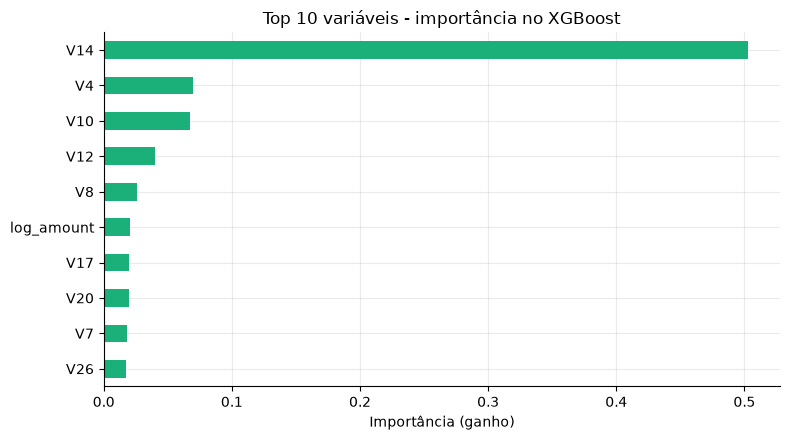

In [18]:
xgb = modelos['XGBoost']
importancia = pd.Series(xgb.feature_importances_, index=X.columns).sort_values(ascending=False)

ax = importancia.head(10).sort_values().plot.barh(color=CORES['XGBoost'], figsize=(8, 4.5))
ax.set(title='Top 10 variáveis - importância no XGBoost', xlabel='Importância (ganho)')
plt.tight_layout()
plt.show()

### 6.2 SHAP: o que pesou em cada decisão
A importância diz *quais* variáveis importam no geral. O **SHAP** diz *em que direção* e *quanto* cada variável
empurrou cada previsão (valores positivos empurram para fraude). Usamos uma amostra do teste com todas as fraudes
para o gráfico ficar rápido.

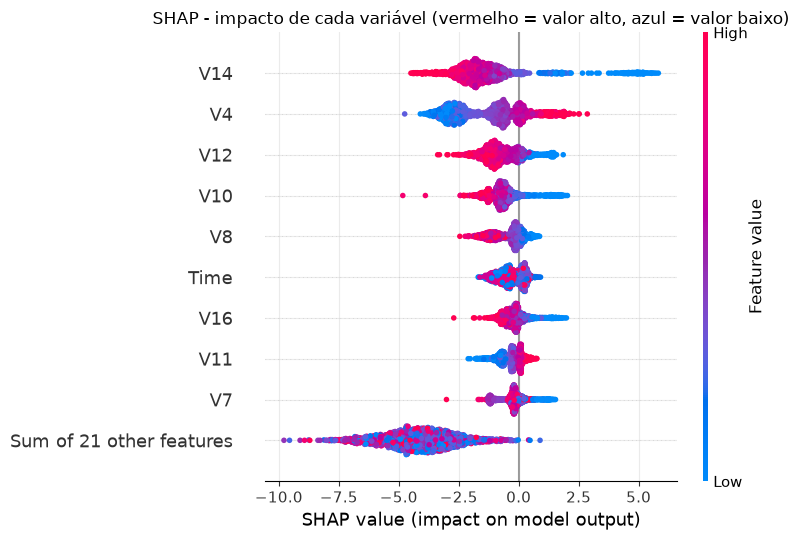

V14   1.8479
V4    1.5488
V12   0.8534
V10   0.8108
V8    0.5071
Name: |SHAP| médio, dtype: float32

In [19]:
explainer = shap.TreeExplainer(xgb)

amostra = pd.concat([
    X_test_sc[y_test == 1],
    X_test_sc[y_test == 0].sample(2000, random_state=SEED),
])
shap_values = explainer(amostra)

shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.title('SHAP - impacto de cada variável (vermelho = valor alto, azul = valor baixo)')
plt.tight_layout()
plt.show()

# Ranking pelo impacto médio (|SHAP| médio)
pd.Series(np.abs(shap_values.values).mean(axis=0), index=X.columns, name='|SHAP| médio') \
    .sort_values(ascending=False).head(5)

#### Explicando uma transação marcada como fraude

Transação 42769: probabilidade de fraude = 100.00% | classe real = 1


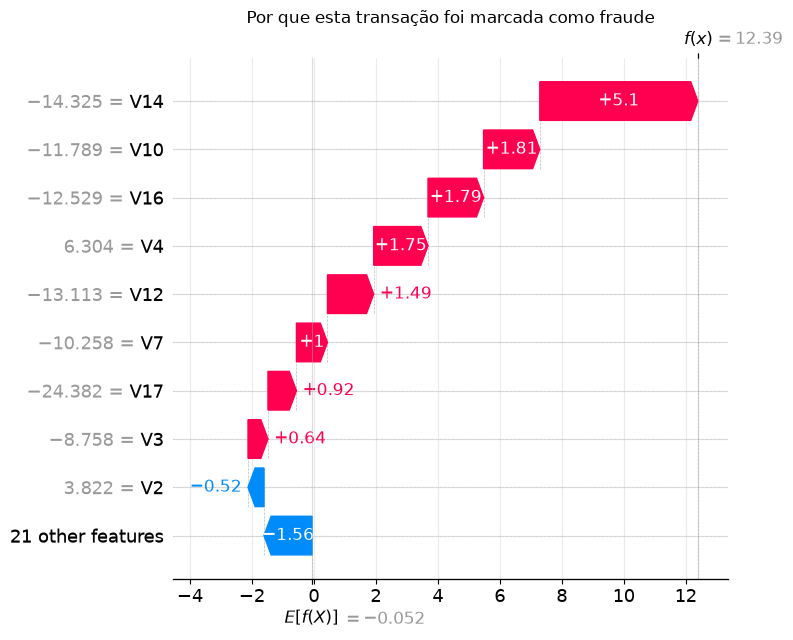

In [20]:
# Pega a fraude real com a maior probabilidade dada pelo XGBoost
proba_xgb = pd.Series(probas['XGBoost'], index=X_test.index)
idx = proba_xgb[y_test == 1].idxmax()
print(f'Transação {idx}: probabilidade de fraude = {proba_xgb[idx]:.2%} | classe real = {y_test[idx]}')

explicacao = explainer(X_test_sc.loc[[idx]])
shap.plots.waterfall(explicacao[0], max_display=10, show=False)
plt.title('Por que esta transação foi marcada como fraude')
plt.tight_layout()
plt.show()

**O que o SHAP mostrou:**
- **`V14` é de longe a variável mais importante.** Valores **baixos** de `V14` (pontos azuis à direita) empurram forte para fraude.
- Depois vêm `V4`, `V12` e `V10`: **`V4` alto** indica fraude; **`V12` e `V10` baixos** indicam fraude.
- Na transação explicada acima, o modelo partiu de um valor base negativo (a maioria das transações é normal) e
  `V14` muito baixo (−14,3, padronizado) sozinho somou **+5,1** ao score. `V10`, `V16`, `V4` e `V12` completaram a decisão.
- Como `V1`–`V28` vêm de PCA, não dá para dizer "o que" `V14` significa no mundo real. Mas o SHAP mostra que o modelo
  decide por padrões consistentes, e não por acaso.

## 7. Evoluções em relação à aula

### 7.1 Undersampling × Oversampling
A regra é testar. Usamos o `Pipeline` do **imbalanced-learn**, que reamostra **apenas os dados de treino**
de cada etapa; o teste continua com a proporção real de fraudes.
- **Undersampling** (`RandomUnderSampler`): joga fora transações normais até empatar com as fraudes.
- **Oversampling** (`SMOTE`): cria fraudes sintéticas até empatar com as normais.

In [21]:
estrategias = {
    'Sem reamostragem': None,
    'Undersampling': RandomUnderSampler(random_state=SEED),
    'Oversampling (SMOTE)': SMOTE(random_state=SEED),
}

resultados_amostragem = {}
for nome, amostrador in estrategias.items():
    etapas = [('scaler', StandardScaler())]
    if amostrador is not None:
        etapas.append(('amostragem', amostrador))
    etapas.append(('modelo', LogisticRegression(max_iter=1000, random_state=SEED)))
    pipe = ImbPipeline(etapas).fit(X_train, y_train)
    resultados_amostragem[nome] = metricas(y_test, pipe.predict_proba(X_test)[:, 1])

pd.DataFrame(resultados_amostragem).T

,Acurácia,Precisão (fraude),Recall (fraude),F1 (fraude),ROC-AUC,PR-AUC,Fraudes pegas,Alarmes falsos
Sem reamostragem,0.9992,0.8312,0.6531,0.7314,0.9595,0.7386,64/98,13
Undersampling,0.9591,0.0373,0.9184,0.0717,0.9766,0.6067,90/98,2324
Oversampling (SMOTE),0.9742,0.0581,0.9184,0.1093,0.9710,0.7215,90/98,1459


**Undersampling × Oversampling:**
- As duas reamostragens levaram o recall da Regressão Logística de 65% para **92% (90 de 98 fraudes)**.
- O **SMOTE** fez isso com bem menos alarmes falsos (1.459 contra 2.324) e manteve a PR-AUC (0,72 contra 0,61 do undersampling).
  O undersampling joga fora 99,8% das transações normais e o modelo perde informação.
- Nesta base, **oversampling (SMOTE) ganhou do undersampling**. O efeito é parecido com usar `class_weight='balanced'`.

### 7.2 Random Forest no Pipeline com ajuste de limiar
Como sugerido na aula, levamos o Random Forest para o `Pipeline` e varremos vários limiares.
O limiar é escolhido **na validação** (um pedaço separado do treino), nunca no teste, para a avaliação final ser honesta.

In [22]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEED
)

pipe_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('modelo', RandomForestClassifier(n_estimators=100, class_weight='balanced',
                                      min_samples_leaf=5, n_jobs=-1, random_state=SEED)),
])
pipe_rf.fit(X_tr, y_tr)
proba_val = pipe_rf.predict_proba(X_val)[:, 1]

limiares = np.round(np.arange(0.1, 0.91, 0.1), 1)
varredura = pd.DataFrame({l: metricas(y_val, proba_val, l) for l in limiares}).T
varredura.index.name = 'limiar'
varredura[['Precisão (fraude)', 'Recall (fraude)', 'F1 (fraude)', 'Fraudes pegas', 'Alarmes falsos']]

,Precisão (fraude),Recall (fraude),F1 (fraude),Fraudes pegas,Alarmes falsos
limiar,,,,,
0.1000,0.3942,0.8283,0.5342,82/99,126
0.2000,0.6639,0.8182,0.7330,81/99,41
0.3000,0.7670,0.7980,0.7822,79/99,24
0.4000,0.8144,0.7980,0.8061,79/99,18
0.5000,0.8280,0.7778,0.8021,77/99,16
0.6000,0.8523,0.7576,0.8021,75/99,13
0.7000,0.8659,0.7172,0.7845,71/99,11
0.8000,0.8816,0.6768,0.7657,67/99,9
0.9000,0.8939,0.5960,0.7152,59/99,7


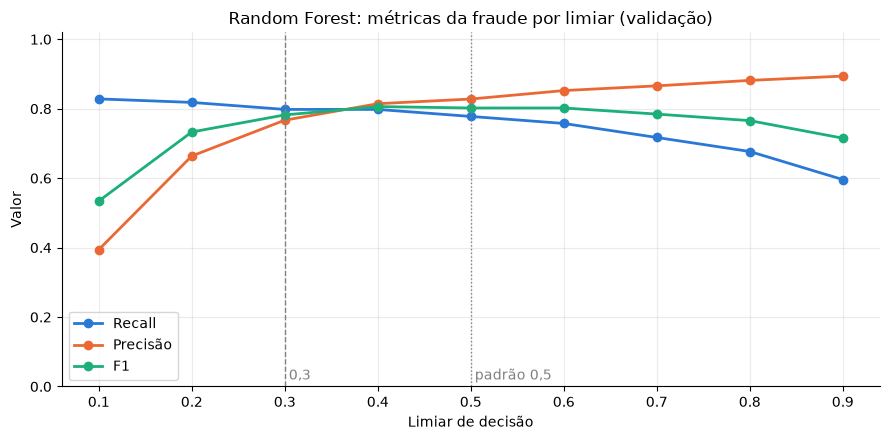

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(limiares, varredura['Recall (fraude)'], marker='o', lw=2, color='#2a78d6', label='Recall')
ax.plot(limiares, varredura['Precisão (fraude)'], marker='o', lw=2, color='#eb6834', label='Precisão')
ax.plot(limiares, varredura['F1 (fraude)'], marker='o', lw=2, color='#1baf7a', label='F1')
ax.axvline(0.5, color='gray', ls=':', lw=1)
ax.axvline(0.3, color='gray', ls='--', lw=1)
ax.text(0.5, 0.02, ' padrão 0,5', color='gray')
ax.text(0.3, 0.02, ' 0,3', color='gray')
ax.set(title='Random Forest: métricas da fraude por limiar (validação)', xlabel='Limiar de decisão', ylabel='Valor', ylim=(0, 1.02))
ax.legend()
plt.tight_layout()
plt.show()

In [24]:
# Limiar escolhido: o de maior F1 na validação
limiar_rf = float(varredura['F1 (fraude)'].astype(float).idxmax())
print(f'Limiar escolhido na validação: {limiar_rf}')

# Reavaliação final no teste (o modelo foi treinado sem ver X_val nem X_test)
proba_rf_teste = pipe_rf.predict_proba(X_test)[:, 1]
pd.DataFrame({
    'RF Pipeline (limiar 0,5)': metricas(y_test, proba_rf_teste, 0.5),
    'RF Pipeline (limiar 0,3)': metricas(y_test, proba_rf_teste, 0.3),
    f'RF Pipeline (limiar escolhido {limiar_rf:.1f})': metricas(y_test, proba_rf_teste, limiar_rf),
}).T

Limiar escolhido na validação: 0.4


,Acurácia,Precisão (fraude),Recall (fraude),F1 (fraude),ROC-AUC,PR-AUC,Fraudes pegas,Alarmes falsos
"RF Pipeline (limiar 0,5)",0.9994,0.7961,0.8367,0.8159,0.9638,0.8404,82/98,21
"RF Pipeline (limiar 0,3)",0.9991,0.6774,0.8571,0.7568,0.9638,0.8404,84/98,40
RF Pipeline (limiar escolhido 0.4),0.9993,0.7568,0.8571,0.8038,0.9638,0.8404,84/98,27


**Random Forest no Pipeline com ajuste de limiar:**
- Na validação, o melhor F1 ficou no **limiar 0,4**.
- No teste, o limiar 0,4 encontrou **84 das 98 fraudes (recall de 85,7%)** com **27 alarmes falsos** (precisão de 75,7%).
  No limiar padrão de 0,5 eram 82 fraudes e 21 alarmes falsos.
- O limiar 0,3 também pega 84 fraudes, mas com 40 alarmes falsos. Para este modelo, 0,4 é melhor que 0,3.

## 8. Conclusão

| Modelo | Limiar | Recall (fraude) | Precisão (fraude) | F1 (fraude) | Fraudes pegas | Alarmes falsos |
|---|---|---|---|---|---|---|
| Regressão Logística | 0,5 | 65,3% | 83,1% | 0,731 | 64/98 | 13 |
| Regressão Logística | 0,3 | 69,4% | 75,6% | 0,723 | 68/98 | 22 |
| Regressão Logística (GridSearch, balanced) | 0,5 | 91,8% | 6,0% | 0,113 | 90/98 | 1.403 |
| Random Forest (balanced) | 0,5 | 83,7% | 75,9% | 0,796 | 82/98 | 26 |
| XGBoost (scale_pos_weight) | 0,5 | 83,7% | 82,8% | **0,832** | 82/98 | 17 |
| **Random Forest no Pipeline** | **0,4** | **85,7%** | 75,7% | 0,804 | **84/98** | 27 |

1. **Acurácia não serve aqui:** o modelo que nunca acusa fraude tem 99,83% de acurácia e recall zero.
2. **Modelos de árvore (Random Forest e XGBoost) foram os melhores**, com recall acima de 83% e precisão acima de 75%.
3. **Limiar escolhido: 0,4 para o Random Forest**, definido na validação. Ele pega 2 fraudes a mais que o 0,5 com 6 alarmes falsos a mais.
4. **Recall sozinho engana tanto quanto a acurácia:** dá para chegar a 92% de recall com 1.400 alarmes falsos.
   A curva de precisão e recall é a ferramenta certa para escolher o ponto de equilíbrio.
5. **SHAP:** `V14` baixo é o principal sinal de fraude, seguido de `V4` alto e `V12`/`V10` baixos.